# Tyre- and fuel-corrected race pace (exploratory)

These analyses are descriptive and exploratory. They were not pre-registered.

Model M1 has one coefficient per driver. That coefficient is the driver's lap time after the fitted effects of compound, tyre age and race lap number are removed. Centred on the drivers in the race, it measures car and driver together, in seconds per lap. Negative is faster than the average of the field in that race.

Caveats: car and driver are not separated. Traffic, damage, team orders and pace management are in the numbers. Wet races are left out. A driver with few clean laps in a race is left out for that race. These are fitted values under this model.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import config as cfg
import expansion_config as xc
import f1deg as F
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
COL = {"SOFT": "#d93025", "MEDIUM": "#c79a00", "HARD": "#4a4f57"}

from pathlib import Path
base = Path("results/pace")
dr = pd.read_csv(base / "driver_race.csv")
ts = pd.read_csv(base / "team_season.csv")
tm = pd.read_csv(base / "teammates.csv")
dv = pd.read_csv(base / "development.csv")
cs = pd.read_csv(base / "compound_season.csv")
print("driver-race rows:", len(dr), " kept:", int(dr["kept"].sum()))
print(dr.groupby("season")["round"].nunique().to_string())

driver-race rows: 1543  kept: 1470
season
2022    18
2023    20
2024    21
2025    21


## Team ranking
Mean team pace over the races of the season, with an indicative interval from resampling races. Fastest first.

2022
 rank            team  races  mean_pace     lo     hi
    1 Red Bull Racing     18     -1.117 -1.257 -0.967
    2         Ferrari     17     -0.975 -1.125 -0.829
    3        Mercedes     18     -0.810 -0.959 -0.654
    4          Alpine     18      0.117  0.048  0.188
    5         McLaren     18      0.304  0.169  0.465
    6      Alfa Romeo     17      0.338  0.179  0.487
    7    Aston Martin     18      0.428  0.279  0.592
    8      AlphaTauri     18      0.445  0.320  0.597
    9    Haas F1 Team     18      0.461  0.368  0.555
   10        Williams     18      0.863  0.735  0.997
2023
 rank            team  races  mean_pace     lo     hi
    1 Red Bull Racing     20     -0.847 -0.977 -0.726
    2         Ferrari     20     -0.397 -0.476 -0.317
    3        Mercedes     20     -0.388 -0.482 -0.290
    4         McLaren     20     -0.182 -0.375  0.009
    5    Aston Martin     20     -0.155 -0.296 -0.026
    6          Alpine     19      0.105  0.026  0.183
    7      AlphaTa

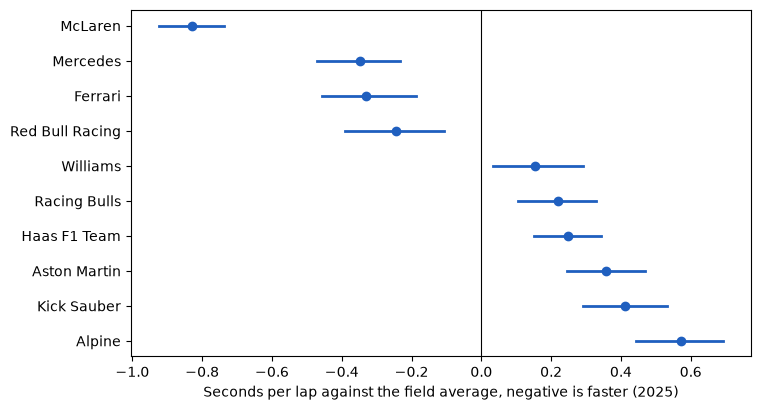

In [2]:
for y in xc.ALL_SEASONS:
    print(y)
    print(ts[ts["season"] == y][["rank", "team", "races", "mean_pace", "lo", "hi"]].round(3).to_string(index=False))
t = ts[ts["season"] == 2025].sort_values("rank")
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, (_, r) in enumerate(t.iterrows()):
    ax.plot([r["lo"], r["hi"]], [i, i], color="#1f5fbf", lw=2)
    ax.plot(r["mean_pace"], i, "o", color="#1f5fbf")
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(len(t))); ax.set_yticklabels(t["team"]); ax.invert_yaxis()
ax.set_xlabel("Seconds per lap against the field average, negative is faster (2025)")
fig.savefig("Images/pace_team_ranking_2025.png", dpi=150, bbox_inches="tight")
plt.show()

## Teammates
The mean of pace A minus pace B over the races both were kept, with A the alphabetically first code. Negative means A was faster.

In [3]:
print(tm[tm["season"] == 2025][["team", "driver_a", "driver_b", "races", "mean_diff", "lo", "hi", "a_faster"]].round(3).to_string(index=False))

           team driver_a driver_b  races  mean_diff     lo     hi  a_faster
        Ferrari      HAM      LEC     20      0.249  0.145  0.357         4
   Haas F1 Team      BEA      OCO     19     -0.130 -0.291  0.036        12
    Kick Sauber      BOR      HUL     14      0.057 -0.149  0.265         7
        McLaren      NOR      PIA     20     -0.005 -0.096  0.078        11
       Mercedes      ANT      RUS     19      0.206  0.060  0.353         5
       Williams      ALB      SAI     18      0.035 -0.101  0.183         9
   Aston Martin      ALO      STR     18     -0.171 -0.314 -0.006        15
   Racing Bulls      HAD      LAW     17     -0.119 -0.276  0.037        10
Red Bull Racing      TSU      VER     18      1.038  0.874  1.193         0
         Alpine      COL      GAS     14      0.080 -0.033  0.199         6


## Development through the season
Least-squares slope of team pace on round number, in seconds per lap per round. Negative means the team got faster against the field.

           team  races   slope      lo      hi
    Kick Sauber     20 -0.0225 -0.0336 -0.0105
   Aston Martin     20 -0.0129 -0.0271  0.0024
       Williams     20 -0.0050 -0.0224  0.0101
   Racing Bulls     21 -0.0017 -0.0153  0.0123
Red Bull Racing     21 -0.0003 -0.0181  0.0206
       Mercedes     21  0.0003 -0.0168  0.0145
   Haas F1 Team     20  0.0021 -0.0136  0.0171
        McLaren     21  0.0051 -0.0077  0.0187
         Alpine     20  0.0133 -0.0071  0.0334
        Ferrari     21  0.0182 -0.0020  0.0386


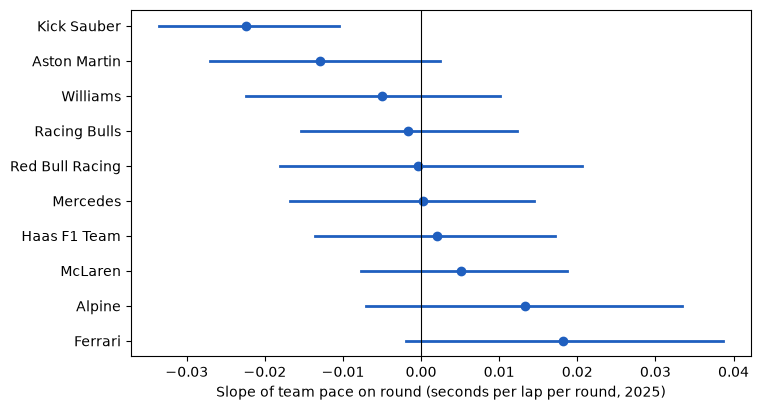

In [4]:
d = dv[dv["season"] == 2025].sort_values("slope")
print(d[["team", "races", "slope", "lo", "hi"]].round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, (_, r) in enumerate(d.iterrows()):
    ax.plot([r["lo"], r["hi"]], [i, i], color="#1f5fbf", lw=2)
    ax.plot(r["slope"], i, "o", color="#1f5fbf")
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(len(d))); ax.set_yticklabels(d["team"]); ax.invert_yaxis()
ax.set_xlabel("Slope of team pace on round (seconds per lap per round, 2025)")
fig.savefig("Images/pace_development_2025.png", dpi=150, bbox_inches="tight")
plt.show()

## Compound comparison
The fitted lap time difference between two compounds at tyre age 5, median over races. They are different physical tyres at different races.

In [5]:
print(cs.round(3).to_string(index=False))

 season        pair  median_diff  races
   2022 HARD-MEDIUM        0.144     16
   2022   HARD-SOFT        0.518      8
   2022 MEDIUM-SOFT        0.294     10
   2023 HARD-MEDIUM        0.030     17
   2023   HARD-SOFT        0.027      5
   2023 MEDIUM-SOFT        0.107      6
   2024 HARD-MEDIUM        0.131     20
   2024   HARD-SOFT        0.009     10
   2024 MEDIUM-SOFT        0.086      9
   2025 HARD-MEDIUM        0.077     20
   2025   HARD-SOFT        0.018     10
   2025 MEDIUM-SOFT        0.044     11


## What this shows and what it does not
This is exploratory. Pace here is the driver coefficient of model M1, centred on the drivers of the race. Car and driver are not separated, and traffic, damage, team orders and pace management are in the numbers.

In each season the ranking puts a small group of teams clearly below zero (faster than the field average) and a group above it. The intervals for neighbouring teams often overlap, so ranks inside a group are not separated by this data. The teammate and development tables use few races per pair or team, and the intervals are wide. The compound comparison mixes different physical tyres at different races. These are fitted values under this model.